<a href="https://colab.research.google.com/github/Mehedi-Hasan-Robel/ML-project/blob/ml-project/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv('/content/Housing.csv')

In [3]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
df.shape

(545, 13)

In [5]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [6]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [8]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [11]:
df.describe(include = 'object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


In [12]:
df.mainroad.unique()

array(['yes', 'no'], dtype=object)

In [13]:
df.	mainroad.value_counts()

,count
mainroad,
yes,468
no,77


In [14]:
df.	mainroad.value_counts(normalize = True)*100

,proportion
mainroad,
yes,85.87156
no,14.12844


In [15]:
df.guestroom.unique()

array(['no', 'yes'], dtype=object)

In [16]:
df.guestroom.value_counts()

,count
guestroom,
no,448
yes,97


In [17]:
df.guestroom.value_counts(normalize = True)*100

,proportion
guestroom,
no,82.201835
yes,17.798165


In [18]:
df.basement.unique()

array(['no', 'yes'], dtype=object)

In [19]:
df.basement.value_counts()

,count
basement,
no,354
yes,191


In [20]:
df.basement.value_counts(normalize = True)*100

,proportion
basement,
no,64.954128
yes,35.045872


In [21]:
df.hotwaterheating.unique()

array(['no', 'yes'], dtype=object)

In [22]:
df.hotwaterheating.value_counts()

,count
hotwaterheating,
no,520
yes,25


In [23]:
df.hotwaterheating.value_counts(normalize = True)*100

,proportion
hotwaterheating,
no,95.412844
yes,4.587156


In [24]:
df.airconditioning.unique()

array(['yes', 'no'], dtype=object)

In [25]:
df.airconditioning.value_counts()

,count
airconditioning,
no,373
yes,172


In [26]:
df.airconditioning.value_counts(normalize = True)*100

,proportion
airconditioning,
no,68.440367
yes,31.559633


In [27]:
df.prefarea.unique()

array(['yes', 'no'], dtype=object)

In [28]:
df.prefarea.value_counts()

,count
prefarea,
no,417
yes,128


In [29]:
df.prefarea.value_counts(normalize = True)*100

,proportion
prefarea,
no,76.513761
yes,23.486239


In [30]:
df.furnishingstatus.unique()

array(['furnished', 'semi-furnished', 'unfurnished'], dtype=object)

In [31]:
df.furnishingstatus.value_counts()

,count
furnishingstatus,
semi-furnished,227
unfurnished,178
furnished,140


In [32]:
df.furnishingstatus.value_counts(normalize = True)*100

,proportion
furnishingstatus,
semi-furnished,41.651376
unfurnished,32.660550
furnished,25.688073


**Outlier Detection**

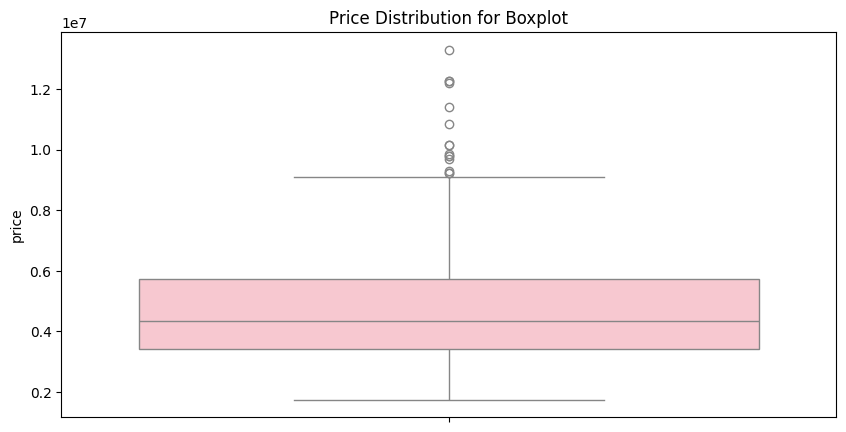

In [33]:
plt.figure(figsize = (10,5))
sns.boxplot(df['price'],color = 'pink')
plt.title('Price Distribution for Boxplot')
plt.tight_layout
plt.show()

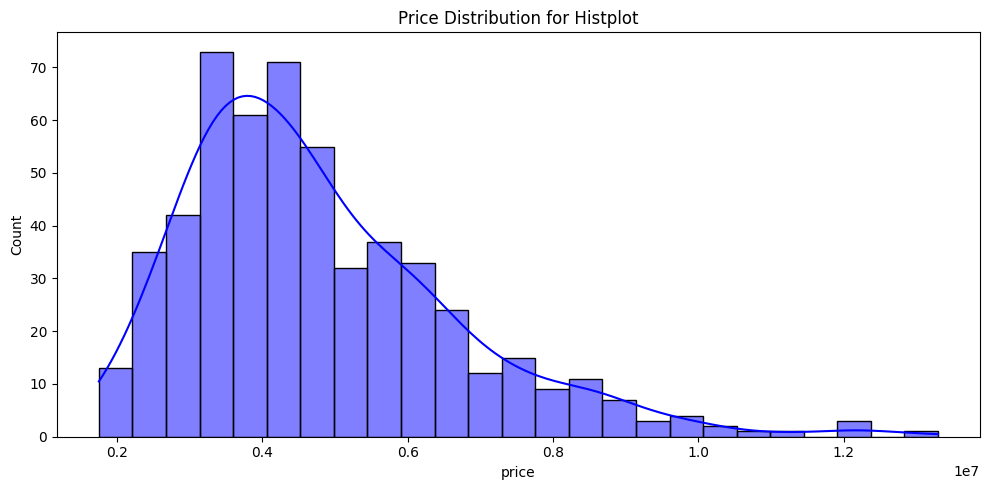

In [34]:
plt.figure(figsize = (10,5))
sns.histplot(df['price'],color = 'blue',bins =25,kde = True)
plt.title('Price Distribution for Histplot')
plt.tight_layout()
plt.show()

In [35]:
max_price = df['price'].max()
min_price = df['price'].min()
q1 = df['price'].quantile(0.25)
q2 = df['price'].quantile(0.50)
q3 = df['price'].quantile(0.75)
iqr = q3 -q1
lower_bound = q1-1.5*iqr
upper_bound = q3+1.5*iqr
print('Maximum Price:',max_price)
print('Minimum Price:',min_price)
print('Q1:',q1)
print('Q2:',q2)
print('Q3:',q3)
print('IQR:',iqr)
print('Lower_Bound:',lower_bound)
print('Upper_Bound:',upper_bound)




Maximum Price: 13300000
Minimum Price: 1750000
Q1: 3430000.0
Q2: 4340000.0
Q3: 5740000.0
IQR: 2310000.0
Lower_Bound: -35000.0
Upper_Bound: 9205000.0


In [36]:
outliers_detect = df[(df['price']<lower_bound)|(df['price']>upper_bound)]

In [37]:
outliers_detect

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


**Outlier Handling**

In [38]:
outlier_handle = df[(df['price']>=lower_bound)&(df['price']<=upper_bound)]

In [39]:
outlier_handle

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
15,9100000,6000,4,1,2,yes,no,yes,no,no,2,no,semi-furnished
16,9100000,6600,4,2,2,yes,yes,yes,no,yes,1,yes,unfurnished
17,8960000,8500,3,2,4,yes,no,no,no,yes,2,no,furnished
18,8890000,4600,3,2,2,yes,yes,no,no,yes,2,no,furnished
19,8855000,6420,3,2,2,yes,no,no,no,yes,1,yes,semi-furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [40]:
df = outlier_handle

In [41]:
df.shape

(530, 13)

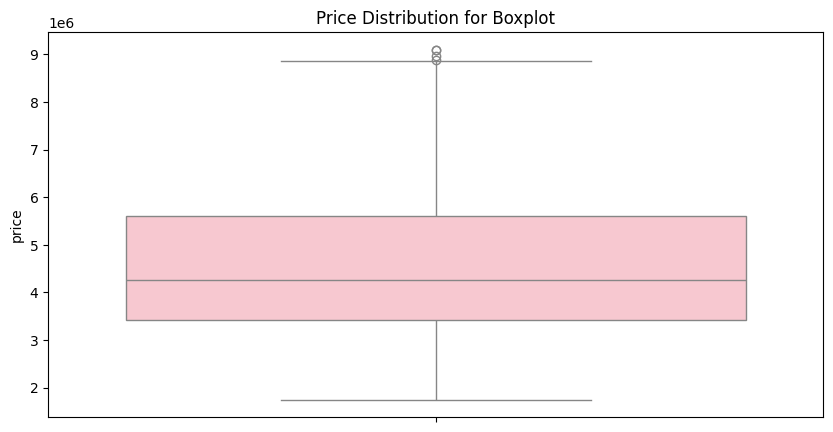

In [42]:
plt.figure(figsize = (10,5))
sns.boxplot(df['price'],color = 'pink')
plt.title('Price Distribution for Boxplot')
plt.tight_layout
plt.show()

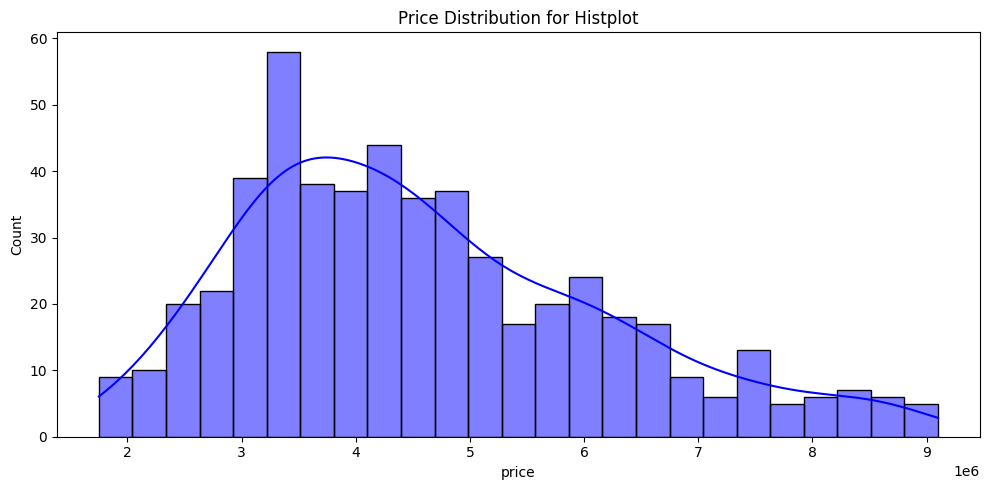

In [43]:
plt.figure(figsize = (10,5))
sns.histplot(df['price'],color = 'blue',bins =25,kde = True)
plt.title('Price Distribution for Histplot')
plt.tight_layout()
plt.show()

**One Hot Encoder**

In [44]:
cat_cols = df.select_dtypes(include = 'object').columns.tolist()

In [45]:
cat_cols

['mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'prefarea',
 'furnishingstatus']

In [46]:
df = pd.get_dummies(df,columns = cat_cols,drop_first=True).astype('int64')

In [47]:
df.head()

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
15,9100000,6000,4,1,2,2,1,0,1,0,0,0,1,0
16,9100000,6600,4,2,2,1,1,1,1,0,1,1,0,1
17,8960000,8500,3,2,4,2,1,0,0,0,1,0,0,0
18,8890000,4600,3,2,2,2,1,1,0,0,1,0,0,0
19,8855000,6420,3,2,2,1,1,0,0,0,1,1,1,0


**Log Transformation**

In [48]:
df['log_price'] = np.log1p(df['price'])
df['log_price']


,log_price
15,16.023785
16,16.023785
17,16.008281
18,16.000438
19,15.996493
...,...
540,14.414348
541,14.384879
542,14.375127
543,14.375127


In [49]:
df.head()

,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished,log_price
15,9100000,6000,4,1,2,2,1,0,1,0,0,0,1,0,16.023785
16,9100000,6600,4,2,2,1,1,1,1,0,1,1,0,1,16.023785
17,8960000,8500,3,2,4,2,1,0,0,0,1,0,0,0,16.008281
18,8890000,4600,3,2,2,2,1,1,0,0,1,0,0,0,16.000438
19,8855000,6420,3,2,2,1,1,0,0,0,1,1,1,0,15.996493


**Feature Selection**

In [50]:
from sklearn.feature_selection import mutual_info_regression

In [51]:
x = df.drop(columns = ['price','log_price'])
y = df['price']

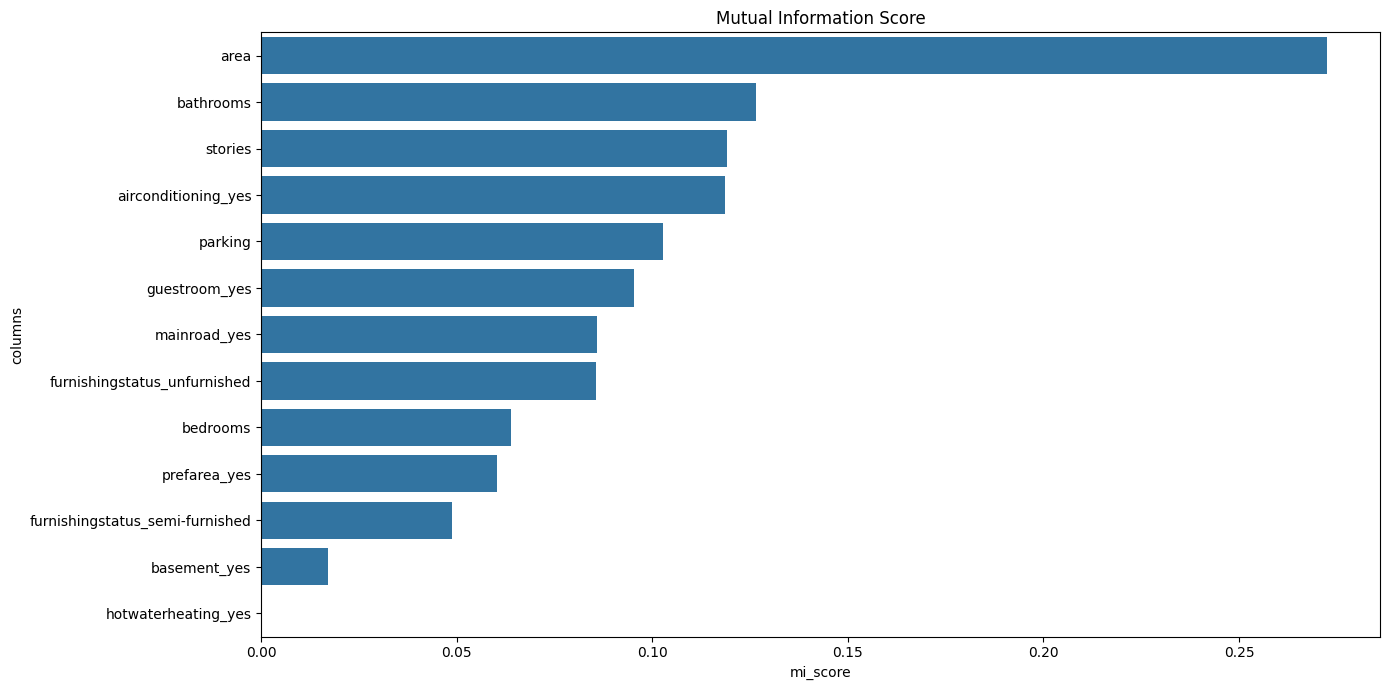

In [52]:
mi = mutual_info_regression(x,y)
mi_df = pd.DataFrame({'columns':x.columns,'mi_score':mi})
mi_sort = mi_df.sort_values(by = 'mi_score',ascending = False,inplace = True)
plt.figure(figsize = (14,7))
sns.barplot(x = 'mi_score',y = 'columns',data = mi_df)
plt.title('Mutual Information Score')
plt.tight_layout()
plt.show()

**Train Test Split**

In [53]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,shuffle = True,random_state = 42)

In [54]:
x_train.shape

(424, 13)

In [55]:
y_train.shape

(424,)

In [56]:
x_test.shape

(106, 13)

In [57]:
y_test.shape

(106,)

**Robust Scaler**

In [58]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
x_train_scale = scaler.fit_transform(x_train)
x_test_scale = scaler.transform(x_test)

In [59]:
x_train_scale

array([[ 0.32171582,  2.        ,  0.        , ...,  1.        ,
         0.        ,  0.        ],
       [-0.75067024,  0.        ,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [ 0.55764075,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.76854334,  0.        ,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [-0.37533512,  0.        ,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [-0.28596962,  1.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]])

In [60]:
x_test_scale

array([[ 0.57193923,  0.        ,  1.        , ...,  1.        ,
         0.        ,  0.        ],
       [-0.91152815,  0.        ,  1.        , ...,  1.        ,
         0.        ,  1.        ],
       [ 0.94906166,  0.        ,  1.        , ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 2.14477212, -1.        ,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [-0.58766756,  0.        ,  0.        , ...,  1.        ,
         0.        ,  0.        ],
       [-0.18945487,  0.        ,  0.        , ...,  0.        ,
         0.        ,  1.        ]])

**Linear Regression**

In [61]:
from sklearn.linear_model import LinearRegression

In [62]:
lr = LinearRegression()

In [63]:
lr.fit(x_train_scale,y_train)

LinearRegression()

In [64]:
lr_pred = lr.predict(x_test_scale)

In [65]:
lr.coef_

array([ 559416.16004151,  101584.49498868,  811994.47438564,
        412331.22692024,  169705.31126682,  406359.43487803,
        379603.44169771,  316981.52063075,  799472.32428801,
        763325.21481799,  582649.81556721,  -85352.03077667,
       -328577.53734497])

In [66]:
lr.intercept_

np.float64(3873532.9958417644)

In [67]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score




In [68]:
lr_mse = mean_squared_error(y_test, lr_pred)
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

In [69]:
print('Linear Regression Metrics:')
print('MSE:',lr_mse)
print('MAE:',lr_mae)
print('RMSE:',lr_rmse)
print('R2:',lr_r2)


Linear Regression Metrics:
MSE: 1148203524699.7468
MAE: 784877.2641074937
RMSE: 1071542.5911739331
R2: 0.668400358283336


In [70]:
pd.DataFrame({'Actual':y_test,'Predicted':lr_pred,'Difference':y_test-lr_pred})

,Actual,Predicted,Difference
155,5530000,5.832190e+06,-3.021903e+05
413,3430000,4.746658e+06,-1.316658e+06
21,8680000,6.274860e+06,2.405140e+06
349,3780000,3.852171e+06,-7.217137e+04
337,3920000,4.474905e+06,-5.549051e+05
...,...,...,...
356,3773000,4.924077e+06,-1.151077e+06
446,3150000,4.200180e+06,-1.050180e+06
146,5600000,4.643791e+06,9.562093e+05
353,3780000,4.539763e+06,-7.597633e+05


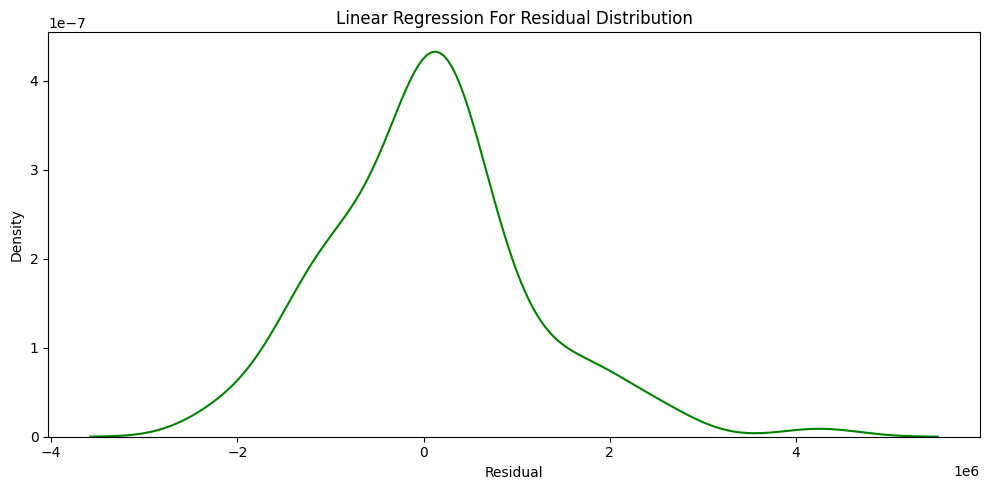

In [71]:
residuals = y_test-lr_pred
plt.figure(figsize = (10,5))
sns.kdeplot(residuals,color = 'g')
plt.xlabel('Residual')
plt.title('Linear Regression For Residual Distribution')
plt.tight_layout()
plt.show()

**Polynimial Regression**

In [72]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
x_train_poly = poly.fit_transform(x_train_scale)
x_test_poly = poly.transform(x_test_scale)

poly_lr = LinearRegression()
poly_lr.fit(x_train_poly, y_train)


poly_pred = poly_lr.predict(x_test_poly)

In [73]:

poly_mse = mean_squared_error(y_test, poly_pred)
poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(poly_mse)
poly_r2 = r2_score(y_test, poly_pred)

print('Polynomial Regression Metrics:')
print('MSE:', poly_mse)
print('MAE:', poly_mae)
print('RMSE:', poly_rmse)
print('R2:', poly_r2)

Polynomial Regression Metrics:
MSE: 1411940660395.845
MAE: 848266.2712708917
RMSE: 1188251.0931599622
R2: 0.5922334263562854


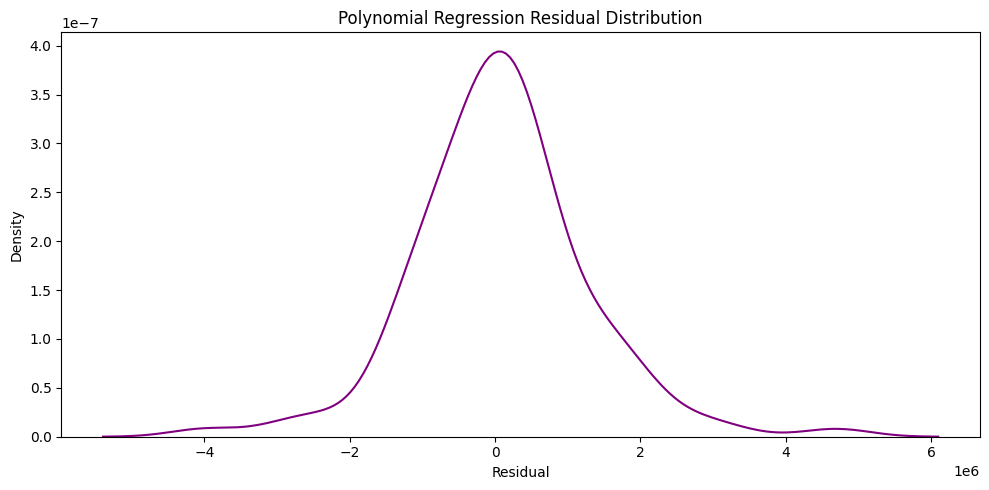

In [74]:

poly_residuals = y_test - poly_pred
plt.figure(figsize=(10, 5))
sns.kdeplot(poly_residuals, color='purple')
plt.xlabel('Residual')
plt.title('Polynomial Regression Residual Distribution')
plt.tight_layout()
plt.show()

**Ridge, Lasso, ElasticNet**

In [75]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet


ridge = Ridge(alpha=0.1)
lasso = Lasso(alpha = 1, max_iter=10000)
elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.7, max_iter=10000)


ridge.fit(x_train_scale, y_train)
lasso.fit(x_train_scale, y_train)
elastic_net.fit(x_train_scale, y_train)


ridge_pred = ridge.predict(x_test_scale)
lasso_pred = lasso.predict(x_test_scale)
elastic_net_pred = elastic_net.predict(x_test_scale)

In [76]:
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_pred)

elastic_net_mse = mean_squared_error(y_test, elastic_net_pred)
elastic_net_mae = mean_absolute_error(y_test, elastic_net_pred)
elastic_net_rmse = np.sqrt(elastic_net_mse)
elastic_net_r2 = r2_score(y_test, elastic_net_pred)

In [77]:
print('Ridge Regression Metrics:')
print('MSE:', ridge_mse)
print('MAE:', ridge_mae)
print('RMSE:', ridge_rmse)
print('R2:', ridge_r2)

Ridge Regression Metrics:
MSE: 1148202783542.0095
MAE: 784861.0736759262
RMSE: 1071542.24533707
R2: 0.668400572328699


In [78]:
print('Lasso Regression Metrics:')
print('MSE:', lasso_mse)
print('MAE:', lasso_mae)
print('RMSE:', lasso_rmse)
print('R2:', lasso_r2)

Lasso Regression Metrics:
MSE: 1148203262282.7327
MAE: 784877.3991174974
RMSE: 1071542.4687256836
R2: 0.6684004340690186


In [79]:
print('Elastic Net Regression Metrics:')
print('MSE:', elastic_net_mse)
print('MAE:', elastic_net_mae)
print('RMSE:', elastic_net_rmse)
print('R2:',   elastic_net_r2)

Elastic Net Regression Metrics:
MSE: 1163556856705.51
MAE: 791550.476896355
RMSE: 1078682.9268628987
R2: 0.6639663365417643


In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


comparison_data = {
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression', 'Elastic Net'],
    'MSE': [lr_mse, poly_mse, ridge_mse, lasso_mse, elastic_net_mse],
    'MAE': [lr_mae, poly_mae, ridge_mae, lasso_mae, elastic_net_mae],
    'RMSE': [lr_rmse, poly_rmse, ridge_rmse, lasso_rmse, elastic_net_rmse],
    'R2 Score': [lr_r2, poly_r2, ridge_r2, lasso_r2, elastic_net_r2]
}


comparison_df = pd.DataFrame(comparison_data)
print(comparison_df)

                   Model           MSE            MAE          RMSE  R2 Score
0      Linear Regression  1.148204e+12  784877.264107  1.071543e+06  0.668400
1  Polynomial Regression  1.411941e+12  848266.271271  1.188251e+06  0.592233
2       Ridge Regression  1.148203e+12  784861.073676  1.071542e+06  0.668401
3       Lasso Regression  1.148203e+12  784877.399117  1.071542e+06  0.668400
4            Elastic Net  1.163557e+12  791550.476896  1.078683e+06  0.663966


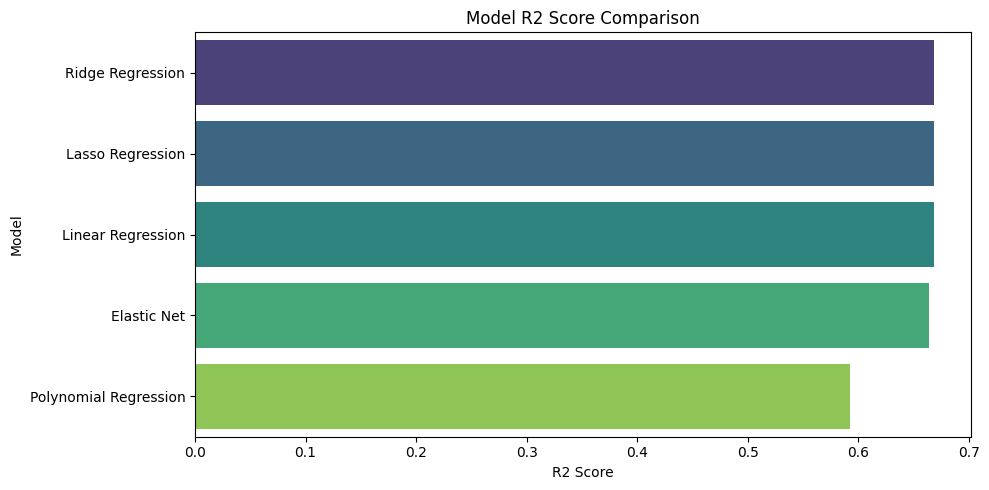

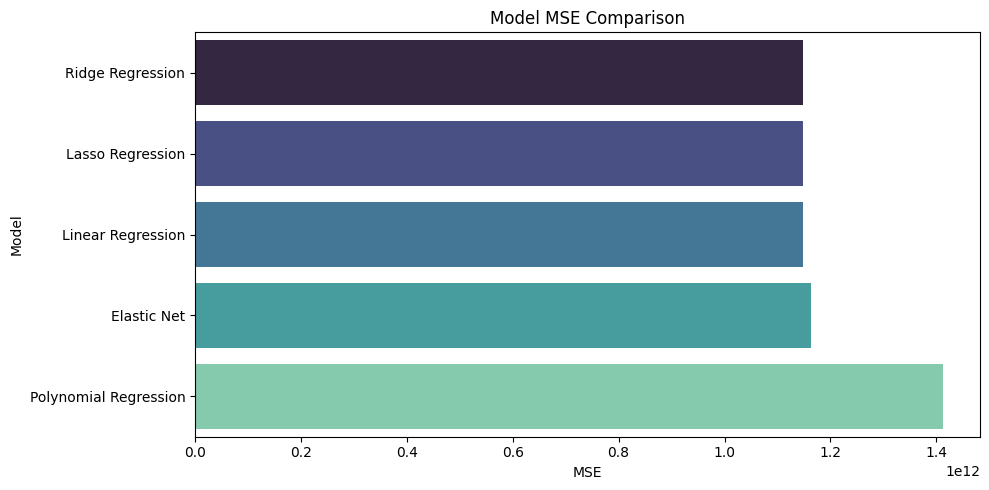

In [81]:

plt.figure(figsize=(10, 5))
sns.barplot(x='R2 Score', y='Model', data=comparison_df.sort_values(by='R2 Score', ascending=False), palette='viridis')

plt.xlabel('R2 Score')
plt.ylabel('Model')
plt.title('Model R2 Score Comparison')
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
sns.barplot(x='MSE', y='Model', data=comparison_df.sort_values(by='MSE'), palette='mako')
plt.title('Model MSE Comparison')
plt.xlabel('MSE')
plt.ylabel('Model')
plt.tight_layout()
plt.show()